In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

df = pd.read_csv("../data/processed/merged.csv", parse_dates=["rated_at"])
df.head()

,userId,movieId,rating,rated_at,rating_year,clean_title,year,genres
0,1,1,4.0,2000-07-30 18:45:03,2000,Toy Story,1995.0,Adventure|Animation|Children|Comedy|Fantasy
1,1,3,4.0,2000-07-30 18:20:47,2000,Grumpier Old Men,1995.0,Comedy|Romance
2,1,6,4.0,2000-07-30 18:37:04,2000,Heat,1995.0,Action|Crime|Thriller
3,1,47,5.0,2000-07-30 19:03:35,2000,Seven (a.k.a. Se7en),1995.0,Mystery|Thriller
4,1,50,5.0,2000-07-30 18:48:51,2000,"Usual Suspects, The",1995.0,Crime|Mystery|Thriller


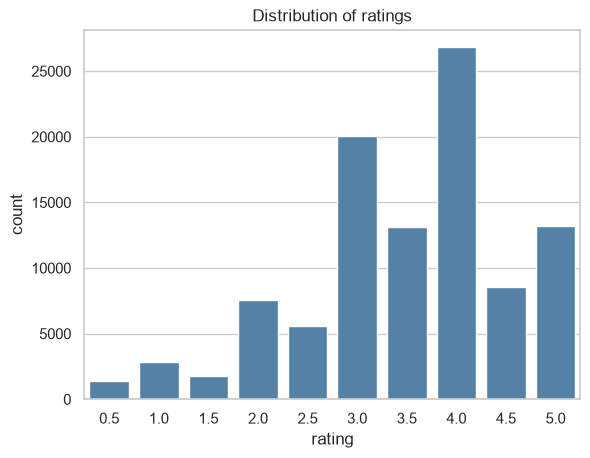

Mean rating: 3.501556983616962
Median rating: 3.5


In [2]:
sns.countplot(data=df, x="rating", color="steelblue")
plt.title("Distribution of ratings")
plt.show()

print("Mean rating:", df["rating"].mean())
print("Median rating:", df["rating"].median())

count     610.000000
mean      165.304918
std       269.480584
min        20.000000
25%        35.000000
50%        70.500000
75%       168.000000
max      2698.000000
dtype: float64


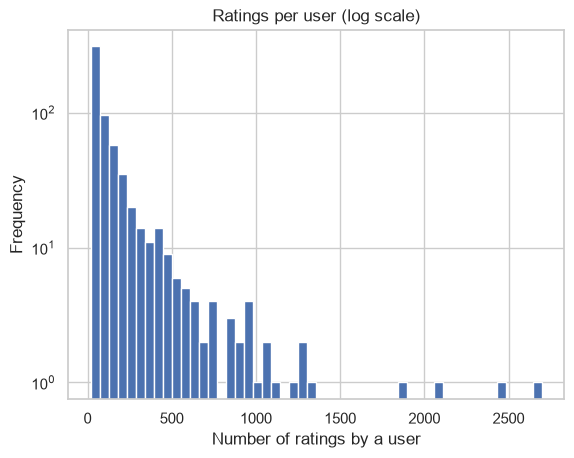

In [3]:
ratings_per_user = df.groupby("userId").size()
print(ratings_per_user.describe())

ratings_per_user.plot(kind="hist", bins=50, log=True)
plt.xlabel("Number of ratings by a user")
plt.title("Ratings per user (log scale)")
plt.show()

count    9724.000000
mean       10.369807
std        22.401005
min         1.000000
25%         1.000000
50%         3.000000
75%         9.000000
max       329.000000
dtype: float64
Movies with only 1 rating: 3446


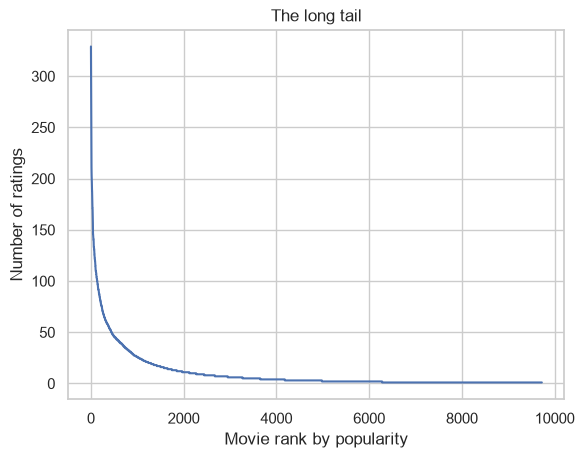

In [4]:
ratings_per_movie = df.groupby("movieId").size()
print(ratings_per_movie.describe())
print("Movies with only 1 rating:", (ratings_per_movie == 1).sum())

ratings_per_movie.sort_values(ascending=False).reset_index(drop=True).plot()
plt.xlabel("Movie rank by popularity")
plt.ylabel("Number of ratings")
plt.title("The long tail")
plt.show()

In [5]:
n_users = df["userId"].nunique()
n_movies = df["movieId"].nunique()
possible = n_users * n_movies
sparsity = 1 - len(df) / possible

print(n_users, n_movies, possible)
print(f"Sparsity: {sparsity:.2%}")

610 9724 5931640
Sparsity: 98.30%


In [6]:
movie_stats = df.groupby("clean_title").agg(
    n_ratings=("rating", "size"),
    avg_rating=("rating", "mean")
)

print(movie_stats.sort_values("avg_rating", ascending=False).head(10))
print(movie_stats[movie_stats["n_ratings"] >= 50].sort_values("avg_rating", ascending=False).head(10))

                                              n_ratings  avg_rating
clean_title                                                        
Zeitgeist: Moving Forward                             1         5.0
'Salem's Lot                                          1         5.0
Death Note: Desu nôto (2006–2007)                     1         5.0
Denise Calls Up                                       1         5.0
Odd Life of Timothy Green, The                        1         5.0
Black Tar Heroin: The Dark End of the Street          1         5.0
Nine Lives of Tomas Katz, The                         1         5.0
Wow! A Talking Fish!                                  1         5.0
World of Glory                                        1         5.0
Bill Hicks: Revelations                               1         5.0
                                                    n_ratings  avg_rating
clean_title                                                              
Shawshank Redemption, The           